# Tugas Praktikum 4 — Association Rule

**Nama:** Firdaus Mangkona  
**NRP:** 5054251003

**Dataset:** *Online Retail* — UCI Machine Learning Repository (541.909 baris, 8 kolom). Transaksi ritel online sebuah toko di Inggris, 1 Desember 2010 – 9 Desember 2011.

**Algoritma:** Apriori (`mlxtend`), `min_support = 0,01` dan `min_confidence = 0,5`.

Notebook ini mengikuti enam langkah praktikum: import dataset, eksplorasi dan pembersihan data, persiapan data transaksi, penerapan algoritma, evaluasi aturan, dan kesimpulan.

## 1. Import Dataset

Kolom yang relevan untuk Association Rule:

| Kolom | Peran |
|---|---|
| `InvoiceNo` | identitas transaksi (satu invoice = satu keranjang) |
| `StockCode` | identitas produk; dipakai sebagai *item* karena unik per produk |
| `Description` | label produk yang dibaca manusia |
| `Quantity`, `UnitPrice` | memvalidasi bahwa baris benar-benar penjualan, bukan retur/penyesuaian |
| `InvoiceDate`, `CustomerID`, `Country` | hanya untuk profil data, tidak masuk perhitungan itemset |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from mlxtend.frequent_patterns import apriori, association_rules

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

df = pd.read_excel("Online Retail.xlsx")
df.shape

(541909, 8)

In [2]:
df.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


Struktur awal: 541.909 baris dan 8 kolom, satu baris = satu produk di dalam satu invoice. `Description` dan `CustomerID` memiliki nilai kosong, dan `InvoiceNo` bertipe objek karena sebagian nomor invoice berawalan `C` (pembatalan).

## 2. Eksplorasi dan Pembersihan Data

In [4]:
print("SEBELUM PEMBERSIHAN")
print(f"  Baris  : {len(df):,}")
print(f"  Invoice: {df['InvoiceNo'].nunique():,}")
print(f"  Produk : {df['StockCode'].nunique():,}")

df.isna().sum()

SEBELUM PEMBERSIHAN
  Baris  : 541,909
  Invoice: 25,900
  Produk : 4,070


InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [5]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


Temuan dari eksplorasi:

1. `Description` kosong pada 1.454 baris — tidak bisa dipakai sebagai item.
2. `Quantity` bernilai negatif sampai −80.995 — baris retur dan pembatalan.
3. `InvoiceNo` berawalan `C` menandai transaksi yang dibatalkan (9.288 baris).
4. `UnitPrice` bernilai negatif sampai −11.062,06 — baris penyesuaian akuntansi, bukan penjualan.
5. Terdapat baris non-produk: ongkir (`POST`, `DOT`), `Manual`, `C2` (carriage), `BANK CHARGES`, `AMAZONFEE`, `PADS`, dan voucher `gift_*`. Baris seperti ini harus dibuang; kalau lolos, ia muncul sebagai aturan dengan confidence tinggi yang tidak punya arti bisnis.

In [6]:
def ringkas(data, label):
    return {"tahap": label,
            "baris": len(data),
            "invoice": data["InvoiceNo"].nunique()}

log = [ringkas(df, "Data awal")]

# 1. Description kosong
df = df.dropna(subset=["Description"])
log.append(ringkas(df, "Hapus Description kosong"))

# 2. Invoice pembatalan (nomor berawalan C)
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
log.append(ringkas(df, "Hapus invoice batal (C)"))

# 3. Quantity negatif atau nol
df = df[df["Quantity"] > 0]
log.append(ringkas(df, "Hapus Quantity <= 0"))

# 4. UnitPrice negatif atau nol: baris penyesuaian, bukan penjualan
df = df[df["UnitPrice"] > 0]
log.append(ringkas(df, "Hapus UnitPrice <= 0"))

# 5. Item non-produk: ongkir, biaya, voucher, manual
NON_PRODUCT = {"POST", "DOT", "M", "m", "C2", "S", "B",
               "BANK CHARGES", "AMAZONFEE", "PADS", "CRUK",
               "ADJUST", "ADJUST2"}
non_produk = (df["StockCode"].isin(NON_PRODUCT)
              | df["StockCode"].str.upper().str.startswith("GIFT_", na=False))
print(f"Baris non-produk dibuang: {int(non_produk.sum()):,} "
      f"({df.loc[non_produk, 'InvoiceNo'].nunique():,} invoice)")
df = df[~non_produk]
log.append(ringkas(df, "Hapus item non-produk"))

tabel_cleaning = pd.DataFrame(log)
tabel_cleaning["baris_dibuang"] = tabel_cleaning["baris"].diff().fillna(0).abs().astype(int)
tabel_cleaning["invoice_dibuang"] = tabel_cleaning["invoice"].diff().fillna(0).abs().astype(int)
tabel_cleaning

Baris non-produk dibuang: 2,346 (2,279 invoice)


,tahap,baris,invoice,baris_dibuang,invoice_dibuang
0,Data awal,541909,25900,0,0
1,Hapus Description kosong,540455,24446,1454,1454
2,Hapus invoice batal (C),531167,20610,9288,3836
3,Hapus Quantity <= 0,530693,20136,474,474
4,Hapus UnitPrice <= 0,530104,19960,589,176
5,Hapus item non-produk,527758,19773,2346,187


In [7]:
awal, akhir = tabel_cleaning.iloc[0], tabel_cleaning.iloc[-1]
print("SEBELUM vs SESUDAH PEMBERSIHAN")
print(f"  Baris  : {awal['baris']:,} -> {akhir['baris']:,} "
      f"({akhir['baris'] - awal['baris']:,} baris, "
      f"{100 * (akhir['baris'] - awal['baris']) / awal['baris']:.1f}%)")
print(f"  Invoice: {awal['invoice']:,} -> {akhir['invoice']:,} "
      f"({akhir['invoice'] - awal['invoice']:,} invoice, "
      f"{100 * (akhir['invoice'] - awal['invoice']) / awal['invoice']:.1f}%)")

SEBELUM vs SESUDAH PEMBERSIHAN
  Baris  : 541,909 -> 527,758 (-14,151 baris, -2.6%)
  Invoice: 25,900 -> 19,773 (-6,127 invoice, -23.7%)


Pembersihan mempertahankan **97,3% baris** tetapi hanya **76,3% invoice**. Selisih besar pada jumlah invoice berasal dari invoice yang seluruh isinya retur atau pembatalan: setelah filter `Quantity > 0`, invoice tersebut tidak menyisakan satu baris pun dan otomatis hilang. Ini perilaku yang benar — invoice tanpa penjualan bukan keranjang belanja.

Data yang dipakai pada tahap berikutnya: **527.758 baris** dan **19.773 invoice** unik.

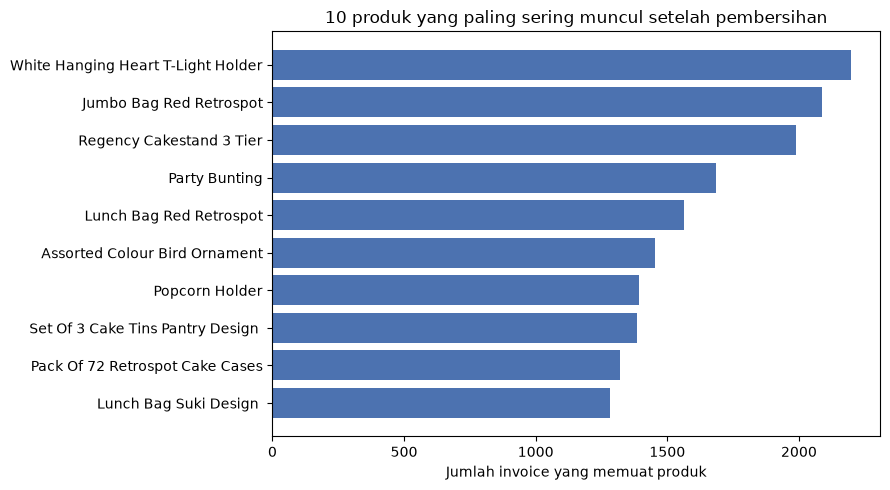

In [8]:
produk_favorit = (df.drop_duplicates(["InvoiceNo", "StockCode"])["StockCode"]
                    .value_counts().head(10))
nama_produk = df.groupby("StockCode")["Description"].agg(lambda s: s.value_counts().idxmax())
label_favorit = [nama_produk[k] for k in produk_favorit.index]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([n.title() for n in label_favorit[::-1]], produk_favorit.values[::-1], color="#4C72B0")
ax.set_xlabel("Jumlah invoice yang memuat produk")
ax.set_title("10 produk yang paling sering muncul setelah pembersihan")
plt.tight_layout()
plt.show()

## 3. Persiapan Data untuk Association Rule

Data diubah menjadi matriks **basket** boolean: baris = invoice, kolom = produk, nilai `True` jika produk ada di invoice tersebut.

Satu `StockCode` bisa memiliki beberapa penulisan `Description` (contoh: kode 20713 tercatat dengan 6 deskripsi berbeda). Jika `Description` dipakai sebagai item, satu produk akan terpecah menjadi beberapa item, support-nya menurun, dan aturan yang terbentuk jadi tidak stabil. Karena itu itemset dihitung pada `StockCode`, sedangkan `Description` hanya dipakai untuk menampilkan hasil.

In [9]:
transaksi = df.groupby("InvoiceNo")["StockCode"].apply(list)
print(f"Jumlah transaksi    : {len(transaksi):,}")
print(f"Rata-rata item      : {transaksi.apply(len).mean():.2f} produk per invoice")
print(f"Invoice terbesar    : {transaksi.apply(len).max():,} produk")
transaksi.head()

Jumlah transaksi    : 19,773
Rata-rata item      : 26.69 produk per invoice
Invoice terbesar    : 1,112 produk


InvoiceNo
536365    [85123A, 71053, 84406B, 84029G, 84029E, 22752,...
536366                                       [22633, 22632]
536367    [84879, 22745, 22748, 22749, 22310, 84969, 226...
536368                         [22960, 22913, 22912, 22914]
536369                                              [21756]
Name: StockCode, dtype: object

In [10]:
basket = (df.assign(dibeli=1)
            .pivot_table(index="InvoiceNo", columns="StockCode",
                         values="dibeli", aggfunc="max", fill_value=0)
            .astype(bool))

print(f"Matriks basket : {basket.shape[0]:,} transaksi x {basket.shape[1]:,} produk")
print(f"Kepadatan      : {basket.values.mean():.4f} (proporsi sel bernilai True)")
basket.iloc[:3, :8]

Matriks basket : 19,773 transaksi x 3,907 produk
Kepadatan      : 0.0067 (proporsi sel bernilai True)


StockCode,10002,10080,10120,10125,10133,10135,11001,15030
InvoiceNo,,,,,,,,
536365,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False


## 4. Penerapan Algoritma Apriori

Support sebuah itemset adalah proporsi transaksi yang memuat seluruh item di dalamnya:

$$\text{supp}(X) = \frac{|\{t : X \subseteq t\}|}{|T|}$$

Apriori memakai sifat *downward closure*: jika sebuah itemset frequent, semua subsetnya frequent; jika ada subset yang infrequent, semua superset-nya pasti infrequent. Kandidat dibangkitkan per level dan dipangkas dengan sifat ini, sehingga tidak perlu memeriksa seluruh $2^{p}$ kemungkinan kombinasi produk.

In [11]:
MIN_SUPPORT = 0.01
MIN_CONFIDENCE = 0.5

ambang_invoice = int(np.ceil(MIN_SUPPORT * len(basket)))
print(f"min_support = {MIN_SUPPORT} -> itemset harus muncul di >= {ambang_invoice} invoice")

frequent_itemsets = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True)
frequent_itemsets["panjang"] = frequent_itemsets["itemsets"].apply(len)

print(f"Frequent itemset: {len(frequent_itemsets):,}")
frequent_itemsets["panjang"].value_counts().sort_index().rename("jumlah itemset").to_frame().T

min_support = 0.01 -> itemset harus muncul di >= 198 invoice


Frequent itemset: 2,007


panjang,1,2,3,4,5
jumlah itemset,829,894,258,25,1


In [12]:
rules = association_rules(frequent_itemsets, metric="confidence",
                          min_threshold=MIN_CONFIDENCE)

print(f"Aturan asosiasi: {len(rules):,}")
print(f"Lift  : min {rules['lift'].min():.2f} | median {rules['lift'].median():.2f} | maks {rules['lift'].max():.2f}")
print(f"Support: min {rules['support'].min():.4f} | maks {rules['support'].max():.4f}")

Aturan asosiasi: 956
Lift  : min 4.74 | median 12.03 | maks 78.77
Support: min 0.0100 | maks 0.0417


Dengan 19.773 invoice, `min_support = 0,01` berarti sebuah itemset harus muncul pada minimal **198 invoice**. Hasilnya **2.007 frequent itemset** dan **956 aturan**.

Jumlah ini tidak terlalu sedikit dan tidak terlalu banyak: masih bisa diperiksa dan diurutkan secara manual, sementara sebagian besar aturan tetap punya lift yang berarti (200 aturan dengan lift > 20, 615 aturan dengan lift > 10). Karena itu nilai awal `min_support = 0,01` dan `min_confidence = 0,5` dipertahankan tanpa penyesuaian.

## 5. Evaluasi Aturan Asosiasi

Confidence mengukur seberapa sering konsekuen muncul jika anteseden muncul:

$$\text{conf}(X \to Y) = \frac{\text{supp}(X \cup Y)}{\text{supp}(X)}$$

Confidence tidak memperhitungkan popularitas konsekuen, sehingga produk yang memang laris akan selalu punya confidence tinggi. Lift menormalkan hal itu:

$$\text{lift}(X \to Y) = \frac{\text{conf}(X \to Y)}{\text{supp}(Y)} = \frac{\text{supp}(X \cup Y)}{\text{supp}(X)\,\text{supp}(Y)}$$

Nilai lift 1 berarti kedua sisi independen, di atas 1 berarti berasosiasi positif, di bawah 1 berarti saling menghindar.

In [13]:
def nama(itemset):
    return "{" + ", ".join(sorted(nama_produk[c] for c in itemset)) + "}"

def tabel_aturan(data):
    out = data.copy()
    out["antecedent"] = out["antecedents"].apply(nama)
    out["consequent"] = out["consequents"].apply(nama)
    return out[["antecedent", "consequent", "support", "confidence",
                "lift", "leverage", "conviction"]].reset_index(drop=True)

aturan = rules.sort_values("lift", ascending=False).reset_index(drop=True)
tabel_aturan(aturan).head(10).round(4)

,antecedent,consequent,support,confidence,lift,leverage,conviction
0,{HERB MARKER THYME},"{HERB MARKER PARSLEY, HERB MARKER ROSEMARY}",0.0103,0.8565,78.7738,0.0101,6.8948
1,"{HERB MARKER PARSLEY, HERB MARKER ROSEMARY}",{HERB MARKER THYME},0.0103,0.9442,78.7738,0.0101,17.7019
2,{HERB MARKER ROSEMARY},"{HERB MARKER PARSLEY, HERB MARKER THYME}",0.0103,0.8458,78.5195,0.0101,6.4166
3,"{HERB MARKER PARSLEY, HERB MARKER THYME}",{HERB MARKER ROSEMARY},0.0103,0.9531,78.5195,0.0101,21.0415
4,{HERB MARKER ROSEMARY},"{HERB MARKER BASIL, HERB MARKER THYME}",0.0101,0.8333,78.4643,0.0100,5.9363
5,"{HERB MARKER BASIL, HERB MARKER THYME}",{HERB MARKER ROSEMARY},0.0101,0.9524,78.4643,0.0100,20.7451
6,"{HERB MARKER BASIL, HERB MARKER ROSEMARY}",{HERB MARKER THYME},0.0101,0.9346,77.9723,0.0100,15.1025
7,{HERB MARKER THYME},"{HERB MARKER BASIL, HERB MARKER ROSEMARY}",0.0101,0.8439,77.9723,0.0100,6.3361
8,{HERB MARKER THYME},{HERB MARKER ROSEMARY},0.0112,0.9325,76.8255,0.0110,14.6327
9,{HERB MARKER ROSEMARY},{HERB MARKER THYME},0.0112,0.9208,76.8255,0.0110,12.4802


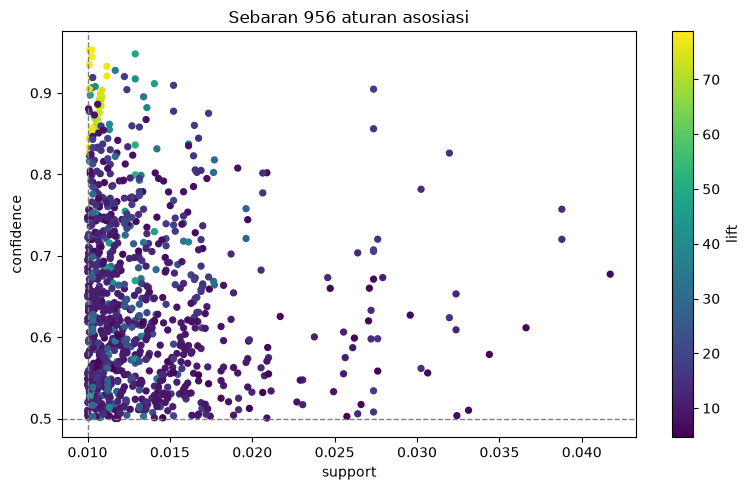

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
titik = ax.scatter(rules["support"], rules["confidence"],
                   c=rules["lift"], cmap="viridis", s=18)
ax.set_xlabel("support")
ax.set_ylabel("confidence")
ax.set_title(f"Sebaran {len(rules):,} aturan asosiasi")
ax.axvline(MIN_SUPPORT, color="gray", linestyle="--", linewidth=1)
ax.axhline(MIN_CONFIDENCE, color="gray", linestyle="--", linewidth=1)
fig.colorbar(titik, ax=ax, label="lift")
plt.tight_layout()
plt.show()

Mayoritas aturan menumpuk di support 1–2% dengan confidence 0,5–0,75. Aturan dengan lift sangat tinggi berada di kiri atas grafik: support kecil tetapi confidence tinggi. Pola ini penting — **lift tinggi hampir selalu berarti support rendah**, karena lift membandingkan terhadap produk yang memang jarang dibeli.

In [15]:
# Satu itemset bisa melahirkan beberapa aturan (arah dan potongan yang berbeda).
# Ambil lift tertinggi per itemset agar tiga aturan terbaik tidak merupakan
# permutasi dari aturan yang sama.
aturan["itemset"] = aturan.apply(
    lambda r: frozenset(r["antecedents"]) | frozenset(r["consequents"]), axis=1)

tiga_terbaik = aturan.drop_duplicates("itemset").head(3).copy()
tampil = tabel_aturan(tiga_terbaik)
tampil.insert(2, "invoice", (tiga_terbaik["support"] * len(basket)).round().astype(int).values)
tampil.round(4)

,antecedent,consequent,invoice,support,confidence,lift,leverage,conviction
0,{HERB MARKER THYME},"{HERB MARKER PARSLEY, HERB MARKER ROSEMARY}",203,0.0103,0.8565,78.7738,0.0101,6.8948
1,{HERB MARKER ROSEMARY},"{HERB MARKER BASIL, HERB MARKER THYME}",200,0.0101,0.8333,78.4643,0.0100,5.9363
2,{HERB MARKER THYME},{HERB MARKER ROSEMARY},221,0.0112,0.9325,76.8255,0.0110,14.6327


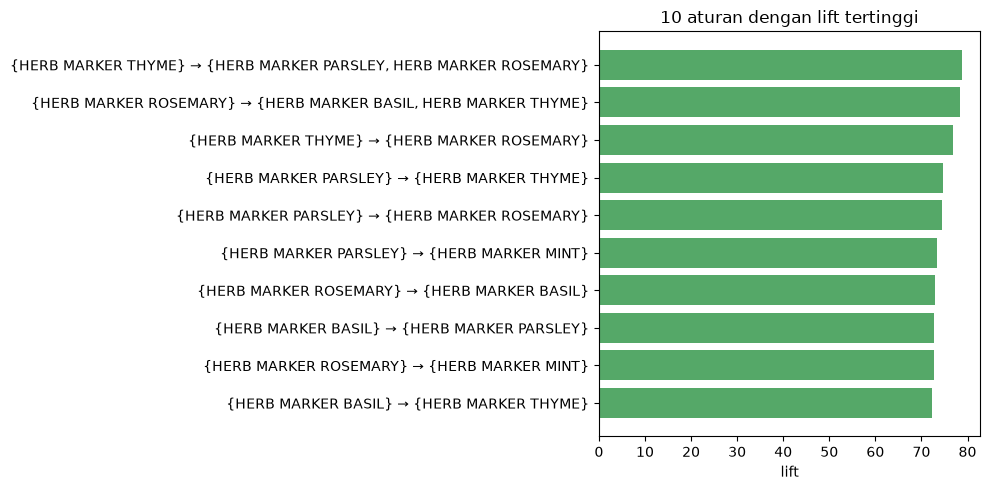

In [16]:
sepuluh = aturan.drop_duplicates("itemset").head(10)
label_aturan = [f"{r.antecedent} → {r.consequent}" for r in tabel_aturan(sepuluh).itertuples()]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(label_aturan[::-1], sepuluh["lift"].values[::-1], color="#55A868")
ax.set_xlabel("lift")
ax.set_title("10 aturan dengan lift tertinggi")
plt.tight_layout()
plt.show()

### Tiga aturan terbaik berdasarkan lift

**1. `{HERB MARKER THYME} → {HERB MARKER PARSLEY, HERB MARKER ROSEMARY}`**  
support 1,03% (203 invoice) · confidence 85,65% · lift 78,77

Dari seluruh invoice yang memuat herb marker thyme, 85,65% juga memuat parsley dan rosemary. Kombinasi ini muncul 78,77 kali lebih sering daripada yang diharapkan jika ketiga produk dibeli secara independen. Pembeli satu desain herb marker cenderung langsung melengkapi dengan dua desain lainnya.

**2. `{HERB MARKER ROSEMARY} → {HERB MARKER BASIL, HERB MARKER THYME}`**  
support 1,01% (200 invoice) · confidence 83,33% · lift 78,46

Delapan dari sepuluh pembeli rosemary juga membeli basil dan thyme. Arah sebaliknya (`{basil, thyme} → {rosemary}`) bahkan memiliki confidence 95,24%, jadi hubungannya timbal balik dan simetris — ciri khas produk yang dibeli sebagai satu set.

**3. `{HERB MARKER THYME} → {HERB MARKER ROSEMARY}`**  
support 1,12% (221 invoice) · confidence 93,25% · lift 76,83

Aturan dua item dengan confidence tertinggi di antara ketiganya: 93,25% pembeli thyme juga membeli rosemary. Lift 76,83 berarti asosiasi ini 77 kali lebih kuat daripada kebetulan.

**Interpretasi bisnis.** Kelima desain herb marker (basil, mint, parsley, rosemary, thyme) pada dasarnya satu lini produk yang dijual terpisah. Pelanggan membelinya sebagai satu set, bukan sebagai produk pengganti. Tindakan yang bisa diambil:

1. Menampilkan kelima desain dalam satu grup pada halaman kategori, bukan tersebar.
2. Membuat bundling "beli 3 desain" dengan harga khusus.
3. Memasang rekomendasi *sering dibeli bersama* pada halaman tiap desain.

**Catatan pembacaan.** Ketiga aturan teratas menunjuk ke keluarga produk yang sama. Itu konsekuensi wajar dari pemeringkatan lift: itemset dengan support kecil mendapat lift besar karena pembaginya kecil. Support ketiganya hanya sekitar 1% (200–221 dari 19.773 invoice), jadi polanya sangat kuat tetapi volumenya kecil. Aturan ini cocok untuk rekomendasi produk, bukan untuk kampanye massal.

In [17]:
# Aturan dengan volume terbesar: support tinggi, lift sedang.
# Ini yang paling berdampak untuk promosi karena menyentuh banyak transaksi.
tabel_aturan(rules.sort_values("support", ascending=False)).head(5).round(4)

,antecedent,consequent,support,confidence,lift,leverage,conviction
0,{JUMBO BAG PINK POLKADOT},{JUMBO BAG RED RETROSPOT},0.0417,0.6773,6.4112,0.0352,2.7718
1,{GREEN REGENCY TEACUP AND SAUCER},{ROSES REGENCY TEACUP AND SAUCER },0.0388,0.7572,14.0575,0.0360,3.8961
2,{ROSES REGENCY TEACUP AND SAUCER },{GREEN REGENCY TEACUP AND SAUCER},0.0388,0.7202,14.0575,0.0360,3.3907
3,{JUMBO STORAGE BAG SUKI},{JUMBO BAG RED RETROSPOT},0.0366,0.6115,5.7879,0.0303,2.3020
4,{JUMBO SHOPPER VINTAGE RED PAISLEY},{JUMBO BAG RED RETROSPOT},0.0344,0.5787,5.4778,0.0281,2.1230


Perbandingan yang penting: aturan jumbo bag `{JUMBO BAG PINK POLKADOT} → {JUMBO BAG RED RETROSPOT}` punya lift jauh lebih rendah (6,41) tetapi support 4,17% — sekitar **825 invoice**, empat kali lipat aturan herb marker. Untuk keputusan merchandising, aturan dengan volume besar seperti ini justru lebih menguntungkan.

Pola lain yang muncul konsisten adalah keluarga **Regency** (teko, cangkir, piring, sugar bowl, milk jug). Contohnya `{REGENCY TEA PLATE PINK} → {REGENCY TEA PLATE GREEN, REGENCY TEA PLATE ROSES}` dengan lift 51,82, dan `{GREEN REGENCY TEACUP AND SAUCER} → {ROSES REGENCY TEACUP AND SAUCER}` dengan support 3,88% (767 invoice). Polanya sama: pelanggan membeli beberapa varian warna dari satu lini produk, bukan satu varian saja.

Itemset terbesar yang lolos ambang adalah lima varian **Charlotte bag** (`PINK POLKADOT`, `SUKI DESIGN`, `RED RETROSPOT`, `STRAWBERRY`, `WOODLAND`), yang menegaskan pola "satu produk, banyak motif" sebagai struktur utama dataset ini.

## 6. Kesimpulan

1. **Kualitas data menentukan kualitas aturan.** Tanpa membuang invoice batal, `Quantity <= 0`, harga negatif, dan item non-produk, aturan dengan confidence tertinggi adalah `{...} → {DOTCOM POSTAGE}` — ongkir, bukan produk. Setelah pembersihan, 19.773 invoice dan 3.907 produk tersisa, dan seluruh aturan yang terbentuk benar-benar menghubungkan produk.

2. **Pola utama dataset adalah pembelian varian, bukan pasangan produk berbeda.** Aturan terkuat menghubungkan desain-desain dari lini yang sama: herb marker (lift 76–79), Regency tea set (lift 46–52), dan Charlotte bag. Pelanggan Online Retail cenderung mengumpulkan beberapa motif/desain dari satu lini, bukan membeli dua kategori produk yang berbeda.

3. **Lift dan support harus dibaca bersama.** Tiga aturan dengan lift tertinggi hanya menyentuh 200–221 invoice (≈1%), sedangkan aturan jumbo bag dengan lift 6,41 menyentuh 825 invoice. Aturan lift tinggi berguna untuk rekomendasi personal, aturan support tinggi berguna untuk promosi dan penataan rak.

4. **Parameter yang dipakai** (`min_support = 0,01`, `min_confidence = 0,5`) menghasilkan 956 aturan — cukup kaya untuk dianalisis dan masih dapat dibaca manual, sehingga tidak perlu diubah.

**Keterbatasan.** Analisis ini memakai representasi boolean, sehingga jumlah unit yang dibeli diabaikan. Support dihitung per invoice, bukan per pelanggan, sehingga satu pelanggan dengan banyak invoice memberi bobot lebih besar. Selain itu, aturan dengan support mendekati ambang (seperti herb marker di 1,01%) bersifat rapuh: menaikkan `min_support` sedikit saja akan menghilangkannya.